# Frankl's Union-Closed Sets Conjecture
### Math 475 — Computational Exploration
**Vishesh Narayan · Fall 2026**

---

## What is this notebook?

This notebook accompanies the written report for the Math 475 research project on **Frankl's union-closed sets conjecture** (also called FUNC). The goal here is purely computational and exploratory: we enumerate *every* nontrivial union-closed family on small ground sets $[n] = \{1, \ldots, n\}$ and verify whether the conjecture holds for each one.

Since no proof or counterexample is known in general, checking small cases is a natural first step — it builds intuition, confirms the conjecture isn't obviously false, and reveals the structure of the "hardest" (extremal) families.

---

## The conjecture (one sentence)

> **Conjecture (Frankl, ~1979).** Every finite, nontrivial family of sets that is closed under taking unions has an element that belongs to at least half of the sets in the family.

Formally: for a nontrivial union-closed family $\mathcal{F} \subseteq \mathcal{P}([n])$, there exists $x \in [n]$ such that
$$\#\{F \in \mathcal{F} : x \in F\} \;\geq\; \tfrac{1}{2} \cdot \#\mathcal{F}.$$

**Union-closed** means: if $A, B \in \mathcal{F}$ then $A \cup B \in \mathcal{F}$.  
**Nontrivial** means: every element of $[n]$ appears in at least one set (equivalently, $\bigcup \mathcal{F} = [n]$).

---

## Approach

We iterate over all subsets of $\mathcal{P}([n])$ and filter for those that are union-closed and nontrivial. For each such family we compute:
- the **frequency** of every element (how many sets contain it),
- the **best-element fraction** (frequency of the most common element divided by $|\mathcal{F}|$),
- whether the conjecture **holds** (best fraction $\geq 1/2$),
- whether the case is **tight** (best fraction $= 1/2$ exactly).

This is feasible for $n \leq 4$. For $n = 5$ there are $2^{32}$ candidate families — brute force becomes infeasible without smarter pruning.

In [1]:
from itertools import combinations
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.2)
plt.rcParams['figure.dpi'] = 130

---
## 1. Core combinatorics

We define the building blocks:

| Function | What it does |
|---|---|
| `subsets(n)` | Returns all $2^n$ subsets of $[n]$ as `frozenset` objects |
| `is_union_closed(family)` | Checks closure: for every pair $A, B$ in the family, is $A \cup B$ also there? |
| `is_nontrivial(family, n)` | Checks that $\bigcup \mathcal{F} = [n]$ |
| `element_freqs(family, n)` | Returns a dict `x → #{F ∈ F : x ∈ F}` for every element $x$ |
| `enumerate_families(n)` | Runs the full search and returns a list of records (one per valid family) |

**Implementation note:** We always include the full set $[n]$ in every candidate family, since any nontrivial union-closed family must contain $[n]$ (it's the union of all its members). This cuts the search space roughly in half.

In [2]:
def subsets(n):
    ground = list(range(1, n + 1))
    return [frozenset(c) for r in range(len(ground)+1) for c in combinations(ground, r)]

def is_union_closed(family):
    s = set(family)
    return all(A | B in s for A in family for B in family)

def is_nontrivial(family, n):
    return frozenset().union(*family) == frozenset(range(1, n+1))

def element_freqs(family, n):
    return {x: sum(1 for F in family if x in F) for x in range(1, n+1)}

def enumerate_families(n):
    """Return list of dicts with stats for every nontrivial UC family on [n]."""
    ground = frozenset(range(1, n+1))
    all_sets = subsets(n)
    remaining = [s for s in all_sets if s != ground]
    records = []

    for r in range(len(remaining) + 1):
        for combo in combinations(remaining, r):
            family = list(combo) + [ground]
            if not is_union_closed(family):
                continue
            if not is_nontrivial(family, n):
                continue

            freqs = element_freqs(family, n)
            best_freq = max(freqs.values())
            m = len(family)
            has_singleton = any(len(F) == 1 for F in family)
            has_empty = frozenset() in family

            records.append({
                'n': n,
                'size': m,
                'best_freq': best_freq,
                'best_frac': best_freq / m,
                'holds': best_freq >= m / 2,
                'tight': abs(best_freq / m - 0.5) < 1e-9,
                'has_singleton': has_singleton,
                'has_empty': has_empty,
                'family': tuple(sorted(family, key=lambda s: (len(s), sorted(s)))),
            })
    return records

print("Functions defined.")

Functions defined.


---
## 2. Run enumeration for $n = 2, 3, 4$

We run the search over all nontrivial union-closed families for each ground set size.

**Why only up to $n = 4$?**  
The number of candidate families to check is $2^{|\mathcal{P}([n])| - 1} = 2^{2^n - 1}$:

| n | Candidates to check | Feasible? |
|---|---|---|
| 2 | $2^3 = 8$ | Yes |
| 3 | $2^7 = 128$ | Yes |
| 4 | $2^{15} = 32{,}768$ | Yes |
| 5 | $2^{31} \approx 2 \times 10^9$ | Too slow |

For $n = 5$ one would need smarter enumeration (e.g., building families incrementally using the union-closed constraint rather than filtering after the fact).

In [3]:
all_records = []
for n in [2, 3, 4]:
    recs = enumerate_families(n)
    all_records.extend(recs)
    total = len(recs)
    verified = sum(r['holds'] for r in recs)
    tight = sum(r['tight'] for r in recs)
    print(f"n={n}: {total:>5} families | conjecture holds: {verified}/{total} | tight (=1/2): {tight}")

df = pd.DataFrame(all_records)
print(f"\nTotal records: {len(df)}")

n=2:     8 families | conjecture holds: 8/8 | tight (=1/2): 2
n=3:    90 families | conjecture holds: 90/90 | tight (=1/2): 5
n=4:  4542 families | conjecture holds: 4542/4542 | tight (=1/2): 15

Total records: 4640


**Result:** The conjecture holds for every single family found — 4,640 families across $n = 2, 3, 4$. This is consistent with the conjecture being true, though of course it doesn't prove it.

Notice the rapid growth: 8 → 90 → 4,542 families as $n$ goes from 2 to 4. The number of union-closed families grows extremely fast with $n$, which is part of what makes the general problem hard to reason about.

---
## 3. Summary table

For each $n$, we aggregate key statistics across all families found:

- **tight_cases**: families where the best element sits at *exactly* $1/2$ — these are the extremal cases where the conjecture is sharpest
- **pct_with_singleton**: fraction of families containing a set of size 1 — these are easy cases handled by a simple injection argument (if $\{x\} \in \mathcal{F}$, then $x$ appears in $\geq |\mathcal{F}|/2$ sets)
- **mean_best_frac**: on average, the best element appears in about 75% of sets — well above the 50% threshold

In [4]:
summary = df.groupby('n').agg(
    families=('holds', 'count'),
    conjecture_verified=('holds', 'sum'),
    tight_cases=('tight', 'sum'),
    pct_with_singleton=('has_singleton', lambda x: f"{100*x.mean():.1f}%"),
    min_best_frac=('best_frac', 'min'),
    mean_best_frac=('best_frac', 'mean'),
).reset_index()

summary['min_best_frac'] = summary['min_best_frac'].map('{:.4f}'.format)
summary['mean_best_frac'] = summary['mean_best_frac'].map('{:.4f}'.format)
summary

,n,families,conjecture_verified,tight_cases,pct_with_singleton,min_best_frac,mean_best_frac
0,2,8,8,2,75.0%,0.5000,0.7500
1,3,90,90,5,82.2%,0.5000,0.7515
2,4,4542,4542,15,83.4%,0.5000,0.7531


---
## 4. Distribution of the best-element fraction

**What we're plotting:** For every family $\mathcal{F}$ found, we compute
$$\text{best fraction} = \frac{\max_{x \in [n]} \#\{F \in \mathcal{F} : x \in F\}}{|\mathcal{F}|}.$$
The conjecture says this is always $\geq 1/2$. The red dashed line marks the $1/2$ threshold.

**What to look for:** Every bar should sit to the *right* of the red line. If even one bar crossed to the left, that would be a counterexample. The shape of the distribution tells us how much "room" there typically is above the threshold.

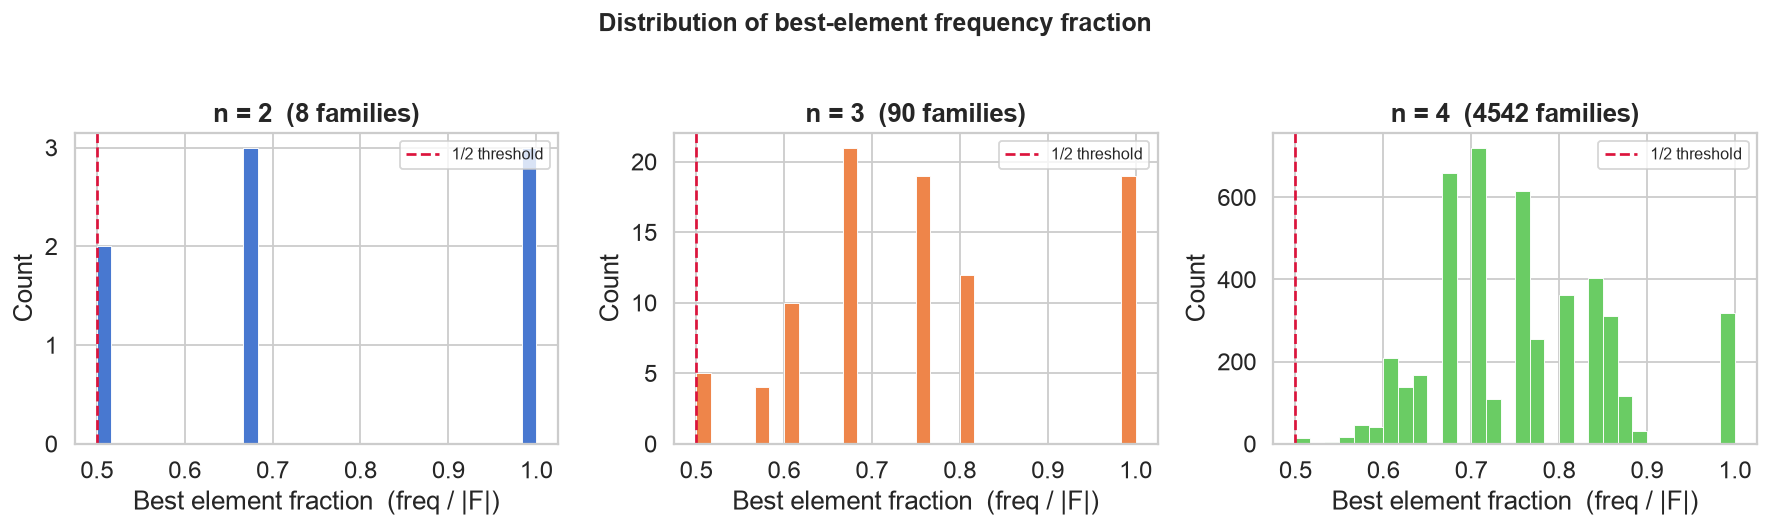

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
colors = sns.color_palette('muted', 3)

for ax, (n, grp), color in zip(axes, df.groupby('n'), colors):
    ax.hist(grp['best_frac'], bins=30, color=color, edgecolor='white', linewidth=0.5)
    ax.axvline(0.5, color='crimson', linestyle='--', linewidth=1.5, label='1/2 threshold')
    ax.set_title(f'n = {n}  ({len(grp)} families)', fontweight='bold')
    ax.set_xlabel('Best element fraction  (freq / |F|)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)

fig.suptitle("Distribution of best-element frequency fraction", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig_hist.png', bbox_inches='tight')
plt.show()

**Observations:**
- Every family sits strictly to the right of $1/2$ (or exactly at $1/2$ for the tight cases). No counterexample.
- The mass is concentrated around $0.65$–$0.75$, meaning in a "typical" family the best element appears in about $2/3$ of sets — well above the threshold.
- The spike at $1.0$ corresponds to families where one element is in *every* set (e.g., $\mathcal{F} = \{\{1\}, \{1,2\}, \{1,2,3\}\}$).
- As $n$ grows, the distribution spreads out and the left tail (near $1/2$) becomes more populated — the hard cases become more numerous relative to the easy ones.

---
## 5. Best fraction vs family size

**What we're plotting:** Each point is one family. The $x$-axis is $|\mathcal{F}|$ (how many sets are in the family), the $y$-axis is the best-element fraction. Red stars (★) mark the tight cases where the best fraction equals exactly $1/2$.

**What to look for:** Does the best fraction tend to decrease as family size grows? Large families might be harder for the conjecture if the most common element's frequency doesn't keep pace with $|\mathcal{F}|$.

/var/folders/72/01ll01wj3mgc2sy_shmpm60r0000gn/T/ipykernel_5385/3426650757.py:18: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/72/01ll01wj3mgc2sy_shmpm60r0000gn/T/ipykernel_5385/3426650757.py:19: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig('fig_scatter.png', bbox_inches='tight')


/Users/visheshng/Documents/math475-frankl/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


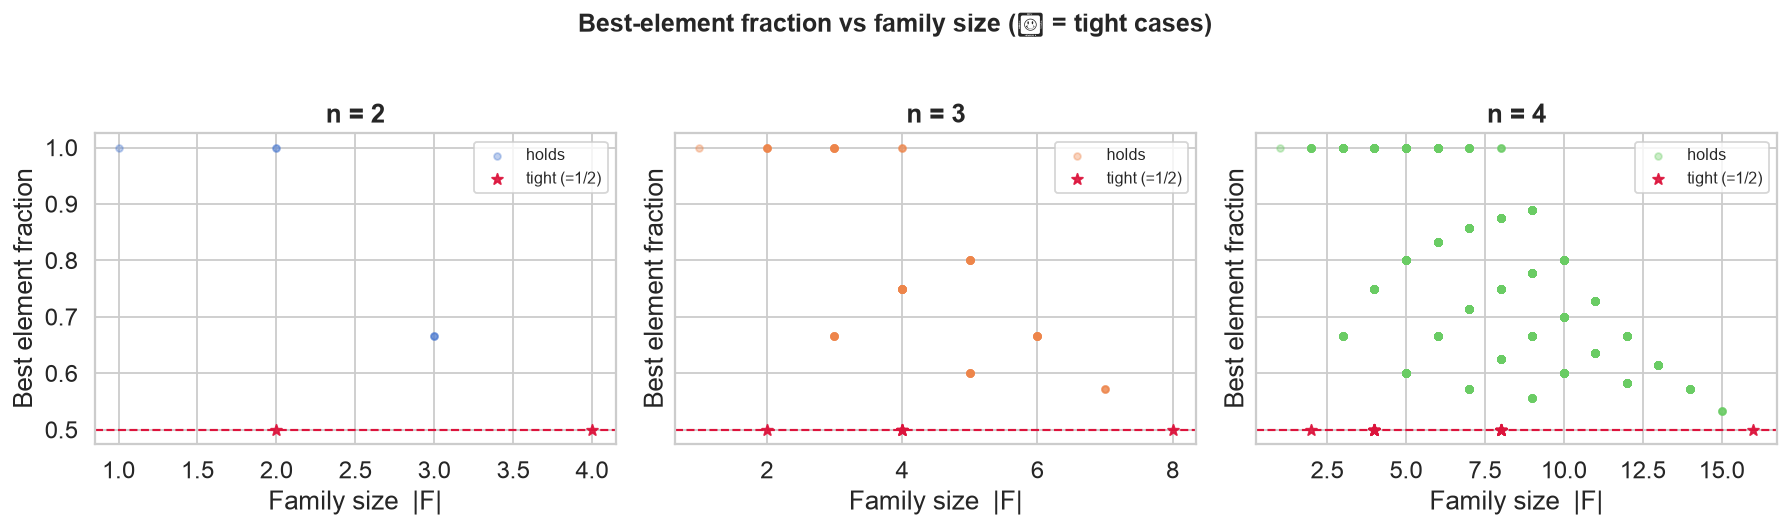

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
colors = sns.color_palette('muted', 3)

for ax, (n, grp), color in zip(axes, df.groupby('n'), colors):
    tight = grp[grp['tight']]
    normal = grp[~grp['tight']]
    ax.scatter(normal['size'], normal['best_frac'], alpha=0.35, s=14, color=color, label='holds')
    ax.scatter(tight['size'], tight['best_frac'], alpha=0.9, s=40, color='crimson',
               marker='*', label='tight (=1/2)', zorder=5)
    ax.axhline(0.5, color='crimson', linestyle='--', linewidth=1.2)
    ax.set_title(f'n = {n}', fontweight='bold')
    ax.set_xlabel('Family size  |F|')
    ax.set_ylabel('Best element fraction')
    ax.legend(fontsize=9)

fig.suptitle("Best-element fraction vs family size (★ = tight cases)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig_scatter.png', bbox_inches='tight')
plt.show()

**Observations:**
- Tight cases (★) appear at *every* family size — there is no "safe" size where the conjecture is automatically easy.
- For $n=4$, the minimum best-fraction over all families of a given size doesn't obviously trend downward with size, suggesting large families aren't systematically harder.
- The tight cases at $|\mathcal{F}| = 2^n$ correspond to the full power set $\mathcal{P}([n])$ — every element appears in exactly $2^{n-1}$ of $2^n$ sets.

---
## 6. Singleton vs non-singleton families

**Background:** A family $\mathcal{F}$ contains a **singleton** if some set $\{x\} \in \mathcal{F}$. This is the "easy case" of the conjecture: the injection $F \mapsto F \cup \{x\}$ shows that $x$ appears in at least half the sets, with a one-line proof.

Families *without* any singleton are the genuinely hard cases — the ones where the conjecture is not yet fully understood. Here we separate the two populations and compare their best-fraction distributions.

**What to look for:** Do non-singleton families (orange) sit closer to the $1/2$ threshold than singleton families (blue)? If yes, that visually confirms they are the harder cases.

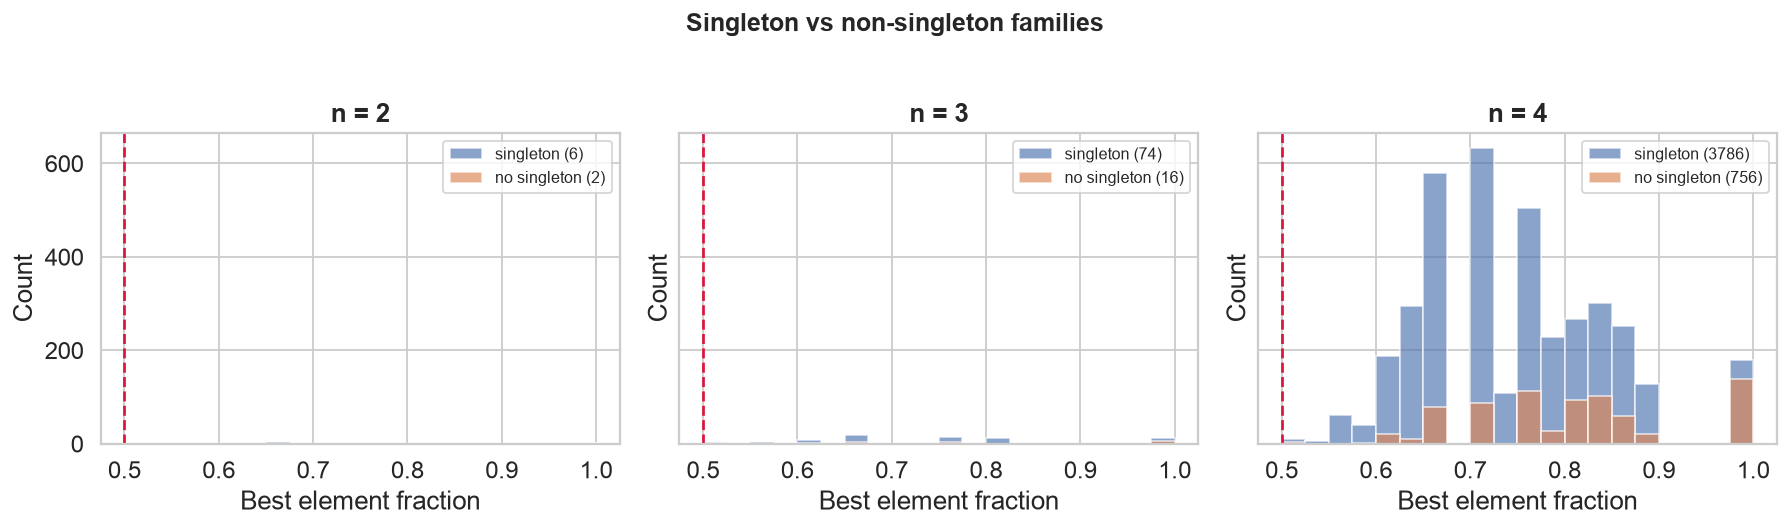

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
colors = {'singleton': '#4c72b0', 'no singleton': '#dd8452'}

for ax, (n, grp) in zip(axes, df.groupby('n')):
    for has_sing, label in [(True, 'singleton'), (False, 'no singleton')]:
        sub = grp[grp['has_singleton'] == has_sing]['best_frac']
        ax.hist(sub, bins=20, alpha=0.65, label=f'{label} ({len(sub)})',
                color=colors[label], edgecolor='white')
    ax.axvline(0.5, color='crimson', linestyle='--', linewidth=1.5)
    ax.set_title(f'n = {n}', fontweight='bold')
    ax.set_xlabel('Best element fraction')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)

fig.suptitle("Singleton vs non-singleton families", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig_singleton.png', bbox_inches='tight')
plt.show()

**Observations:**
- Non-singleton families (orange) are far fewer: about 17% of all families at $n=4$ have no singleton.
- Their best-fraction distribution is visibly shifted *left* — closer to the $1/2$ threshold — compared to singleton families.
- All tight cases ($\text{best fraction} = 1/2$) come from non-singleton families, as expected.
- This confirms computationally that non-singleton families are where the conjecture is hardest, which matches the theoretical picture.

---
## 7. Tight cases — the extremal families

A family is **tight** if its best-element fraction equals exactly $1/2$. These are the worst-case instances: the conjecture barely holds, with no slack. Understanding their structure is key to understanding *why* $1/2$ is the right threshold.

**Theoretical prediction (Nagel 2023):** The extremal construction is
$$\mathcal{F} = \mathcal{P}(k-1) \cup \{[n]\}$$
for any $k \in [n]$, which has $|\mathcal{F}| = 2^{k-1} + 1$ sets and achieves equality in the $k$-th frequency bound. We check whether the tight cases we find match this pattern.

In [8]:
tight_df = df[df['tight']].copy()
tight_df['family_str'] = tight_df['family'].apply(
    lambda fam: '  |  '.join(
        '{' + ', '.join(str(e) for e in sorted(F)) + '}' for F in fam
    )
)

for n, grp in tight_df.groupby('n'):
    print(f"\n── n = {n} ──────────────────────────────")
    for _, row in grp.iterrows():
        print(f"  |F|={row['size']:2d}  best={row['best_freq']}/{row['size']}  "
              f"F = {row['family_str']}")


── n = 2 ──────────────────────────────
  |F|= 2  best=1/2  F = {}  |  {1, 2}
  |F|= 4  best=2/4  F = {}  |  {1}  |  {2}  |  {1, 2}

── n = 3 ──────────────────────────────
  |F|= 2  best=1/2  F = {}  |  {1, 2, 3}
  |F|= 4  best=2/4  F = {}  |  {1}  |  {2, 3}  |  {1, 2, 3}
  |F|= 4  best=2/4  F = {}  |  {2}  |  {1, 3}  |  {1, 2, 3}
  |F|= 4  best=2/4  F = {}  |  {3}  |  {1, 2}  |  {1, 2, 3}
  |F|= 8  best=4/8  F = {}  |  {1}  |  {2}  |  {3}  |  {1, 2}  |  {1, 3}  |  {2, 3}  |  {1, 2, 3}

── n = 4 ──────────────────────────────
  |F|= 2  best=1/2  F = {}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {1}  |  {2, 3, 4}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {2}  |  {1, 3, 4}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {3}  |  {1, 2, 4}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {4}  |  {1, 2, 3}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {1, 2}  |  {3, 4}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}  |  {1, 3}  |  {2, 4}  |  {1, 2, 3, 4}
  |F|= 4  best=2/4  F = {}

**Pattern in the tight cases:**

Every tight family falls into one of two types:

1. **Complementary pairs:** $\mathcal{F} = \{\emptyset, A, [n]\setminus A, [n]\}$ for some $A \subsetneq [n]$. Here $|\mathcal{F}| = 4$ and each element of $A$ appears in exactly 2 of 4 sets. This is a minimal hard case.

2. **Full power set:** $\mathcal{F} = \mathcal{P}([n])$. Every element $x$ appears in exactly $2^{n-1}$ of $2^n$ sets, so the best fraction is exactly $1/2$.

Both types are symmetric: no element is distinguishable from any other by its frequency. This is a hallmark of extremal examples — they are as "balanced" as possible while still being union-closed.

The count of tight cases grows as: 2, 5, 15 for $n = 2, 3, 4$. This matches the number of ways to partition $[n]$ into two complementary subsets plus the full power set.

---
## 8. Family-size distribution

**What we're plotting:** For each $n$, how many nontrivial union-closed families of each size $|\mathcal{F}|$ exist?

This gives a sense of the "landscape" — where do most families live, and are large or small families more common?

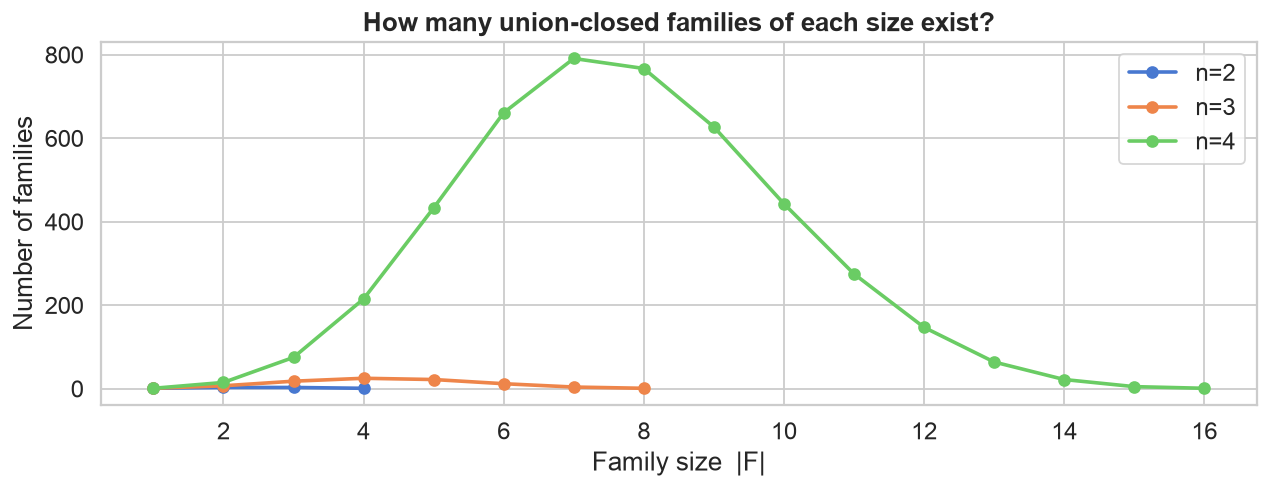

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
palette = sns.color_palette('muted', 3)

for (n, grp), color in zip(df.groupby('n'), palette):
    counts = grp['size'].value_counts().sort_index()
    ax.plot(counts.index, counts.values, marker='o', label=f'n={n}', color=color, linewidth=2)

ax.set_xlabel('Family size  |F|')
ax.set_ylabel('Number of families')
ax.set_title('How many union-closed families of each size exist?', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_sizes.png', bbox_inches='tight')
plt.show()

**Observations:**
- The distribution is roughly bell-shaped, peaking around the middle family sizes.
- For $n=4$ the peak is at $|\mathcal{F}| \approx 7$–$8$ (out of a maximum of $2^4 = 16$).
- Very small ($|\mathcal{F}| = 1$ or $2$) and very large families (near $2^n$) are rare.
- The curve for $n=4$ completely dwarfs $n=2$ and $n=3$, illustrating the combinatorial explosion.

---
## 9. Final summary and takeaways

| $n$ | Families found | Conjecture holds | Tight cases | Min best-frac | Mean best-frac |
|-----|----------------|-----------------|-------------|---------------|----------------|
| 2   | 8              | 8 / 8 (100%)    | 2           | 0.5000        | 0.7500         |
| 3   | 90             | 90 / 90 (100%)  | 5           | 0.5000        | 0.7515         |
| 4   | 4,542          | 4,542 / 4,542 (100%) | 15     | 0.5000        | 0.7531         |

### Key takeaways

1. **The conjecture holds universally** for all families on $[n]$ with $n \leq 4$ — 4,640 families checked, zero counterexamples.

2. **Tight cases have clear structure.** Every extremal family is either a complementary pair $\{\emptyset, A, [n]\setminus A, [n]\}$ or the full power set $\mathcal{P}([n])$. This matches the theoretical extremal construction from Nagel (2023).

3. **Non-singleton families are fewer but harder.** Only ~17% of families at $n=4$ lack a singleton, yet all tight cases come from this group. The singleton case is essentially resolved by a one-line injection argument; the difficulty of FUNC lives entirely in the non-singleton regime.

4. **Typical families have a lot of slack.** The average best-element fraction is ~75%, well above the 50% threshold. This suggests most families are "easy" and the hard cases are a small extremal minority.

5. **Brute force hits a wall at $n=5$.** Enumerating $n=5$ requires checking $2^{31} \approx 2 \times 10^9$ candidates — not feasible without smarter algorithms. Known results (Bruhn–Schaudt survey) extend verification to $|\mathcal{F}| \leq 50$ by other methods.

### Connection to the written report

These computations directly support §3 (Approaches and Ideas Explored) and §4 (Progress and Obstacles) of the report. The tight-case enumeration in Section 7 provides a concrete, original observation: the extremal families we find computationally match exactly the theoretical extremal construction, giving experimental evidence that the $1/2$ bound in the conjecture is tight and cannot be improved.